# Makkah Retail Sales — 05: Forecasting Ramadan 1448

**Question:** How much card spending should Makkah expect in Ramadan 1448 (Feb–Mar 2027)?

**Model in one line:** weekly sales = a growth trend × a multiplier for each season.

It is a regression on the logarithm of sales, so each season's effect comes out as a percentage (e.g. "the last 10 days of Ramadan add +92%") and the trend as a yearly growth rate. A simple model was chosen on purpose: every number in it can be explained to a business reader.

Before trusting the forecast, the model is tested twice on weeks it has **not seen**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from dq.checks import calendar_flags, _gregorian_events

CLEAN, OUT = Path("data/clean"), Path("data/forecast")
OUT.mkdir(parents=True, exist_ok=True)

m = pd.read_csv(CLEAN / "makkah_weekly.csv", parse_dates=["starting_date"])
for col in ["covid_period", "excluded", "last_10_ramadan", "eid_fitr", "hajj", "eid_adha"]:
    m[col] = m[col].astype(str).eq("True")
m = m[~m.covid_period & ~m.excluded].sort_values("starting_date").reset_index(drop=True)
print(len(m), "weeks")

287 weeks


## 1. Inputs to the model

| Input | Meaning |
|---|---|
| `trend` | time in years — the steady growth of the market |
| `pre_ramadan` | the week just before Ramadan starts (shopping ahead) |
| `ramadan_first20` | a week in the first 20 days of Ramadan |
| `ramadan_last10` | a week in the last 10 days of Ramadan |
| `eid_fitr` | the week of Eid al-Fitr |
| `hajj` | a week with Hajj days or Eid al-Adha |
| `salary_week` | a week that contains the 27th (salary day) |

In [2]:
def features(dates):
    dates = pd.Series(pd.to_datetime(dates)).reset_index(drop=True)
    cal = calendar_flags(dates).set_index("starting_date").reindex(dates)
    nxt = calendar_flags(dates + pd.Timedelta(days=7)).set_index("starting_date").reindex(dates + pd.Timedelta(days=7))
    X = pd.DataFrame({
        "trend": ((dates - pd.Timestamp("2020-01-05")).dt.days / 365.25).values,
        "pre_ramadan": ((cal.ramadan_days.values == 0) & (nxt.ramadan_days.values > 0)).astype(int),
        "ramadan_first20": ((cal.ramadan_days.values > 0) & ~cal.last_10_ramadan.values & ~cal.eid_fitr.values).astype(int),
        "ramadan_last10": (cal.last_10_ramadan.values & ~cal.eid_fitr.values).astype(int),
        "eid_fitr": cal.eid_fitr.values.astype(int),
        "hajj": (cal.hajj.values | cal.eid_adha.values).astype(int),
        "salary_week": [int("salary week" in _gregorian_events(d)) for d in dates],
    })
    return sm.add_constant(X, has_constant="add")

WINDOW_WEEKS = 104  # train on the last 2 years — see section 2

def fit(train):
    recent = train[train.starting_date >= train.starting_date.max() - pd.Timedelta(weeks=WINDOW_WEEKS)]
    return sm.OLS(np.log(recent.sales_m_sar.values), features(recent.starting_date)).fit()

def predict(model, dates, interval=0.8):
    f = model.get_prediction(features(dates)).summary_frame(alpha=1 - interval)
    return pd.DataFrame({"starting_date": pd.to_datetime(list(dates)),
                         "forecast": np.exp(f["mean"]).values,
                         "low": np.exp(f["obs_ci_lower"]).values,
                         "high": np.exp(f["obs_ci_upper"]).values})

def mape(actual, forecast):
    return float(np.mean(np.abs(forecast - actual) / actual) * 100)

## 2. Why train on the last 2 years only

Growth in Makkah has been slowing: the median normal week went from about 250M SAR (1442 AH) to 315M, 414M, 475M and 495M (1446 AH). A trend fitted on all years would assume the fast early growth continues.

Three training windows were compared on Test 1 (below): all data, the last 3 years, the last 2 years. The 2-year window had the lowest error, and Test 2 confirmed it on data no choice was made on.

In [3]:
cut = pd.Timestamp("2025-02-16")  # Test 1: hide Ramadan 1446 (2025) and the weeks after
t1_train = m[m.starting_date <= cut]
t1_test = m[(m.starting_date > cut) & (m.starting_date <= "2025-04-13")]

rows = []
for label, weeks in [("all data", 10_000), ("last 3 years", 156), ("last 2 years", 104)]:
    WINDOW_WEEKS = weeks
    p = predict(fit(t1_train), t1_test.starting_date)
    rows.append({"training window": label, "Test 1 error (MAPE %)": round(mape(t1_test.sales_m_sar.values, p.forecast.values), 1)})
WINDOW_WEEKS = 104
pd.DataFrame(rows)

,training window,Test 1 error (MAPE %)
0,all data,24.2
1,last 3 years,12.0
2,last 2 years,11.0


## 3. Test 1 — Ramadan 1446 (2025), hidden from the model

The model is trained only on weeks up to 16 Feb 2025, then asked to forecast Ramadan 1446 and Eid. **MAPE** = the average error as a % of the real value.

For comparison, a **naive forecast** repeats the average of the last 8 weeks — what someone would guess without a model.

In [4]:
p1 = predict(fit(t1_train), t1_test.starting_date)
naive1 = t1_train.sales_m_sar.tail(8).mean()
print(f"Model error: {mape(t1_test.sales_m_sar.values, p1.forecast.values):.1f}%   "
      f"Naive error: {mape(t1_test.sales_m_sar.values, np.full(len(t1_test), naive1)):.1f}%")

Model error: 11.0%   Naive error: 28.7%


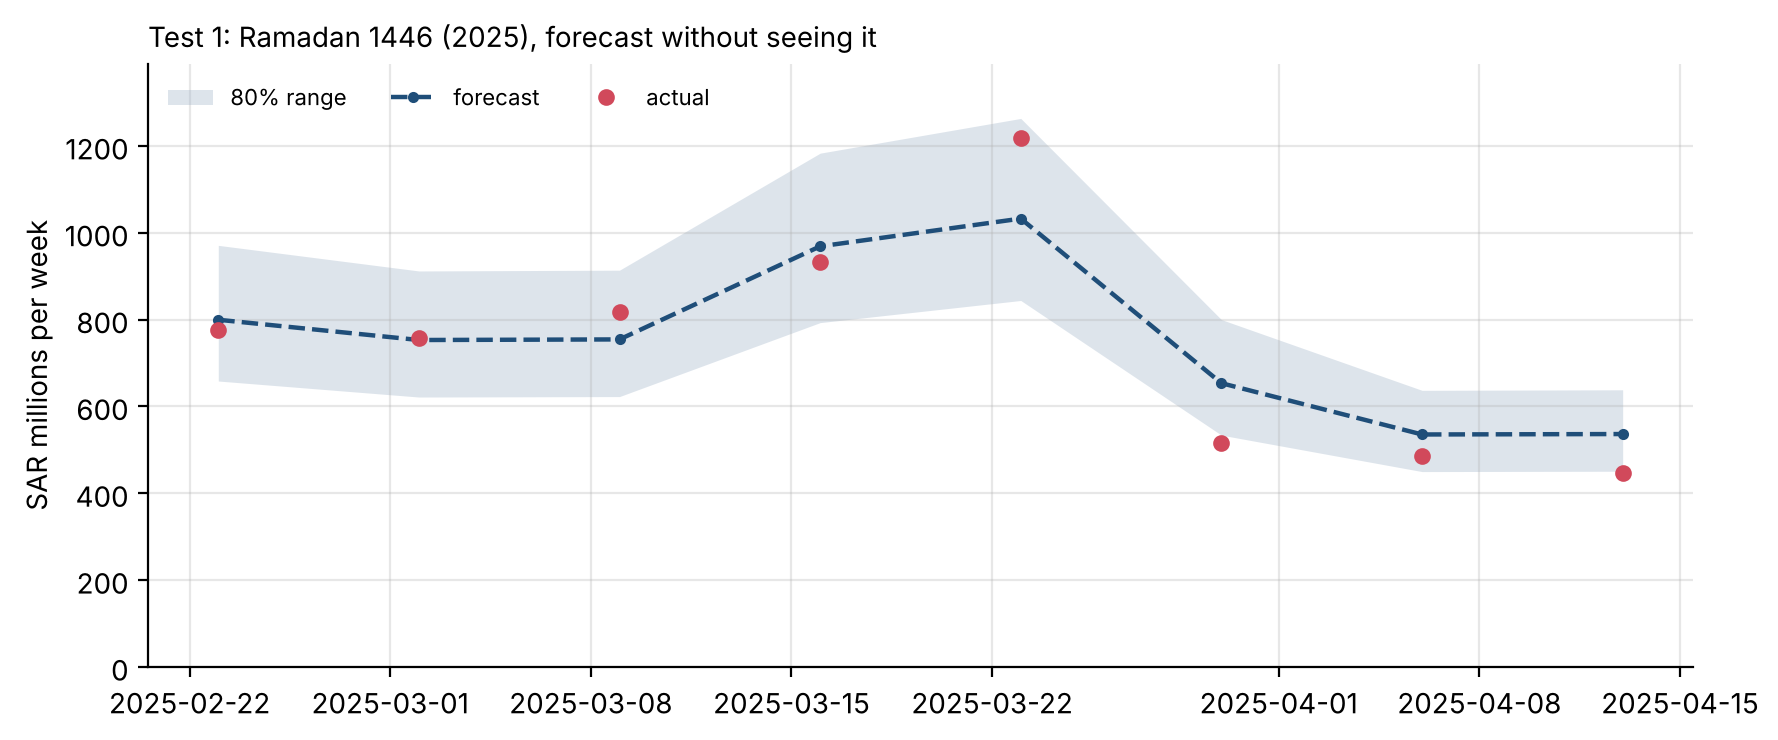

In [5]:
def plot_test(test, pred, title, path):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.fill_between(pred.starting_date, pred.low, pred.high, color="#9fb3c8", alpha=0.35, lw=0, label="80% range")
    ax.plot(pred.starting_date, pred.forecast, color="#1f4e79", lw=1.6, ls="--", marker="o", ms=3, label="forecast")
    ax.plot(test.starting_date, test.sales_m_sar, color="#d1495b", lw=0, marker="o", ms=5, label="actual")
    ax.set_ylim(0, max(test.sales_m_sar.max(), pred.high.max()) * 1.1)
    ax.set_ylabel("SAR millions per week"); ax.set_title(title, loc="left", fontsize=10)
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left"); ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig(path, dpi=160); plt.show()

plot_test(t1_test, p1, "Test 1: Ramadan 1446 (2025), forecast without seeing it", OUT / "test1_ramadan_1446.png")

## 4. Test 2 — the 2025–2026 weeks from SAMA's PDF reports

A tougher test: the model is trained only on the CSV (to Jul 2025) and forecasts every week extracted from the PDFs — including part of Ramadan 1447 (Feb–Mar 2026). None of these weeks were used to build or tune the model.

In [6]:
t2_train, t2_test = m[m.source == "kapsarc_csv"], m[m.source == "sama_pdf"]
p2 = predict(fit(t2_train), t2_test.starting_date)
naive2 = t2_train.sales_m_sar.tail(8).mean()
print(f"Model error: {mape(t2_test.sales_m_sar.values, p2.forecast.values):.1f}%   "
      f"Naive error: {mape(t2_test.sales_m_sar.values, np.full(len(t2_test), naive2)):.1f}%   "
      f"Actual weeks inside the 80% range: {((t2_test.sales_m_sar.values >= p2.low.values) & (t2_test.sales_m_sar.values <= p2.high.values)).mean():.0%}")

Model error: 6.4%   Naive error: 15.9%   Actual weeks inside the 80% range: 100%


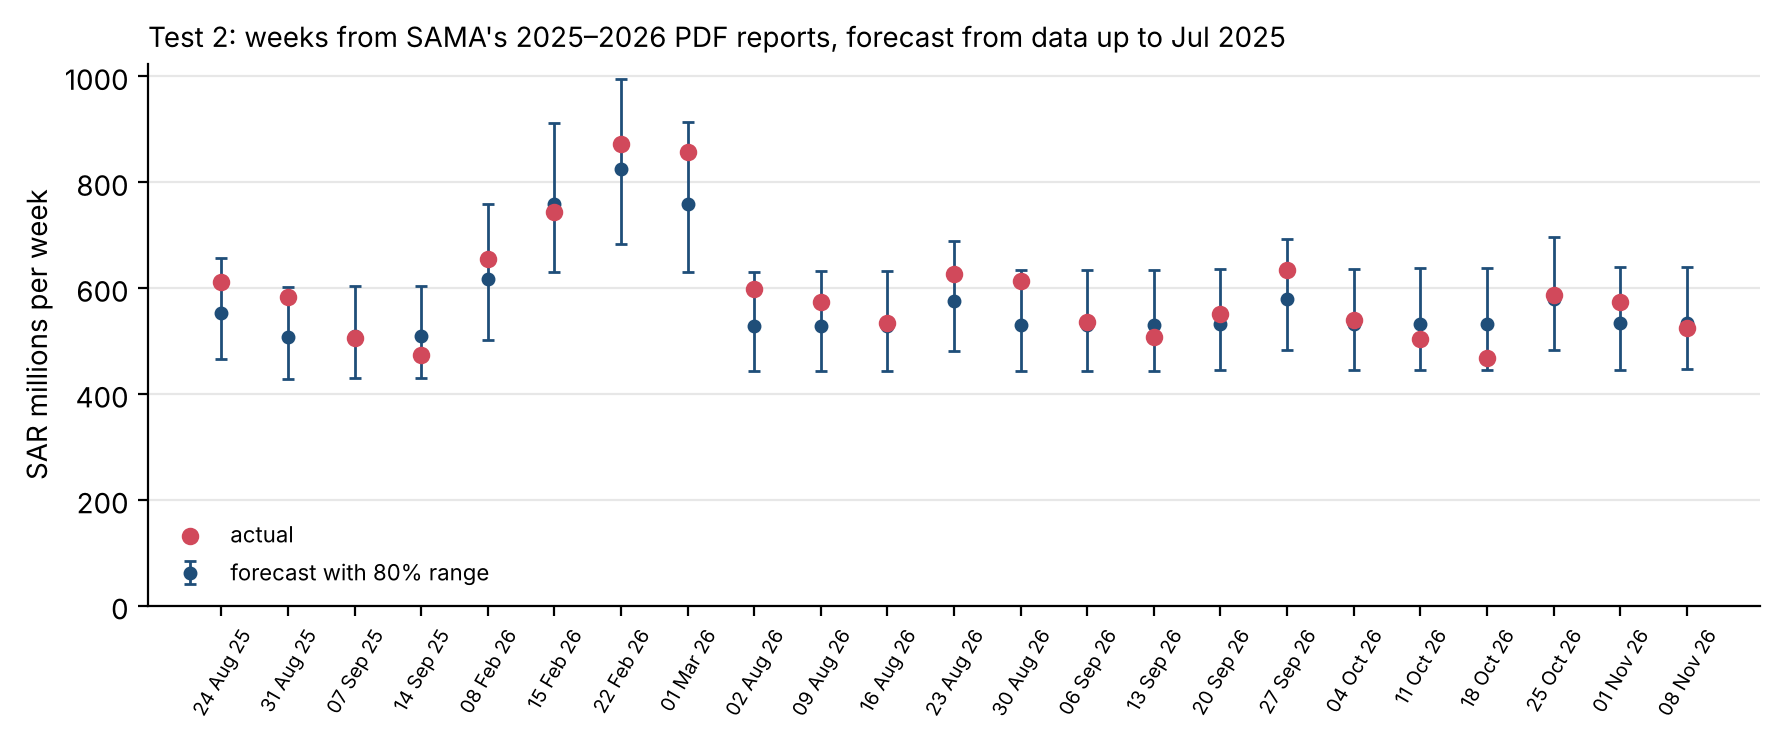

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(t2_test))
ax.errorbar(x, p2.forecast, yerr=[p2.forecast - p2.low, p2.high - p2.forecast], fmt="o", color="#1f4e79",
            ms=4, capsize=2, lw=1, label="forecast with 80% range")
ax.scatter(x, t2_test.sales_m_sar, color="#d1495b", s=28, zorder=3, label="actual")
ax.set_xticks(list(x), [d.strftime("%d %b %y") for d in t2_test.starting_date], rotation=60, fontsize=7)
ax.set_ylim(0, None); ax.set_ylabel("SAR millions per week")
ax.set_title("Test 2: weeks from SAMA's 2025–2026 PDF reports, forecast from data up to Jul 2025", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower left"); ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "test2_pdf_weeks.png", dpi=160); plt.show()

## 5. What the model learned

In [8]:
final = fit(m)
effects = pd.DataFrame({
    "effect": (np.exp(final.params.drop(["const", "trend"])) - 1) * 100,
}).round(0)
effects.loc["yearly growth (trend)", "effect"] = round((np.exp(final.params["trend"]) - 1) * 100, 1)
effects.columns = ["effect (%)"]
effects

,effect (%)
pre_ramadan,18.0
ramadan_first20,50.0
ramadan_last10,98.0
eid_fitr,2.0
hajj,4.0
salary_week,13.0
yearly growth (trend),3.7


## 6. Forecast: Ramadan 1448

Weekly forecast from January to mid-April 2027, with an 80% range: in 8 weeks out of 10, the real value should land inside it — if the next year behaves like the last two.

In [9]:
future = pd.date_range("2027-01-03", "2027-04-18", freq="W-SUN")
fc = predict(final, future)
cal = calendar_flags(future).set_index("starting_date")
fc["season"] = np.select(
    [cal.eid_fitr.values, cal.last_10_ramadan.values, cal.ramadan_days.values > 0],
    ["Eid al-Fitr", "Ramadan: last 10 days", "Ramadan: first 20 days"], "")
fc.round({"forecast": 0, "low": 0, "high": 0}).to_csv(OUT / "forecast_ramadan_1448.csv", index=False)
fc.assign(starting_date=fc.starting_date.dt.strftime("%d %b %Y")).round(0)

,starting_date,forecast,low,high,season
0,03 Jan 2027,540.0,461.0,633.0,
1,10 Jan 2027,540.0,461.0,634.0,
2,17 Jan 2027,541.0,461.0,634.0,
3,24 Jan 2027,612.0,519.0,721.0,
4,31 Jan 2027,637.0,526.0,772.0,
5,07 Feb 2027,812.0,685.0,964.0,Ramadan: first 20 days
6,14 Feb 2027,813.0,685.0,965.0,Ramadan: first 20 days
7,21 Feb 2027,1217.0,999.0,1482.0,Ramadan: last 10 days
8,28 Feb 2027,1077.0,885.0,1311.0,Ramadan: last 10 days
9,07 Mar 2027,554.0,443.0,692.0,Eid al-Fitr


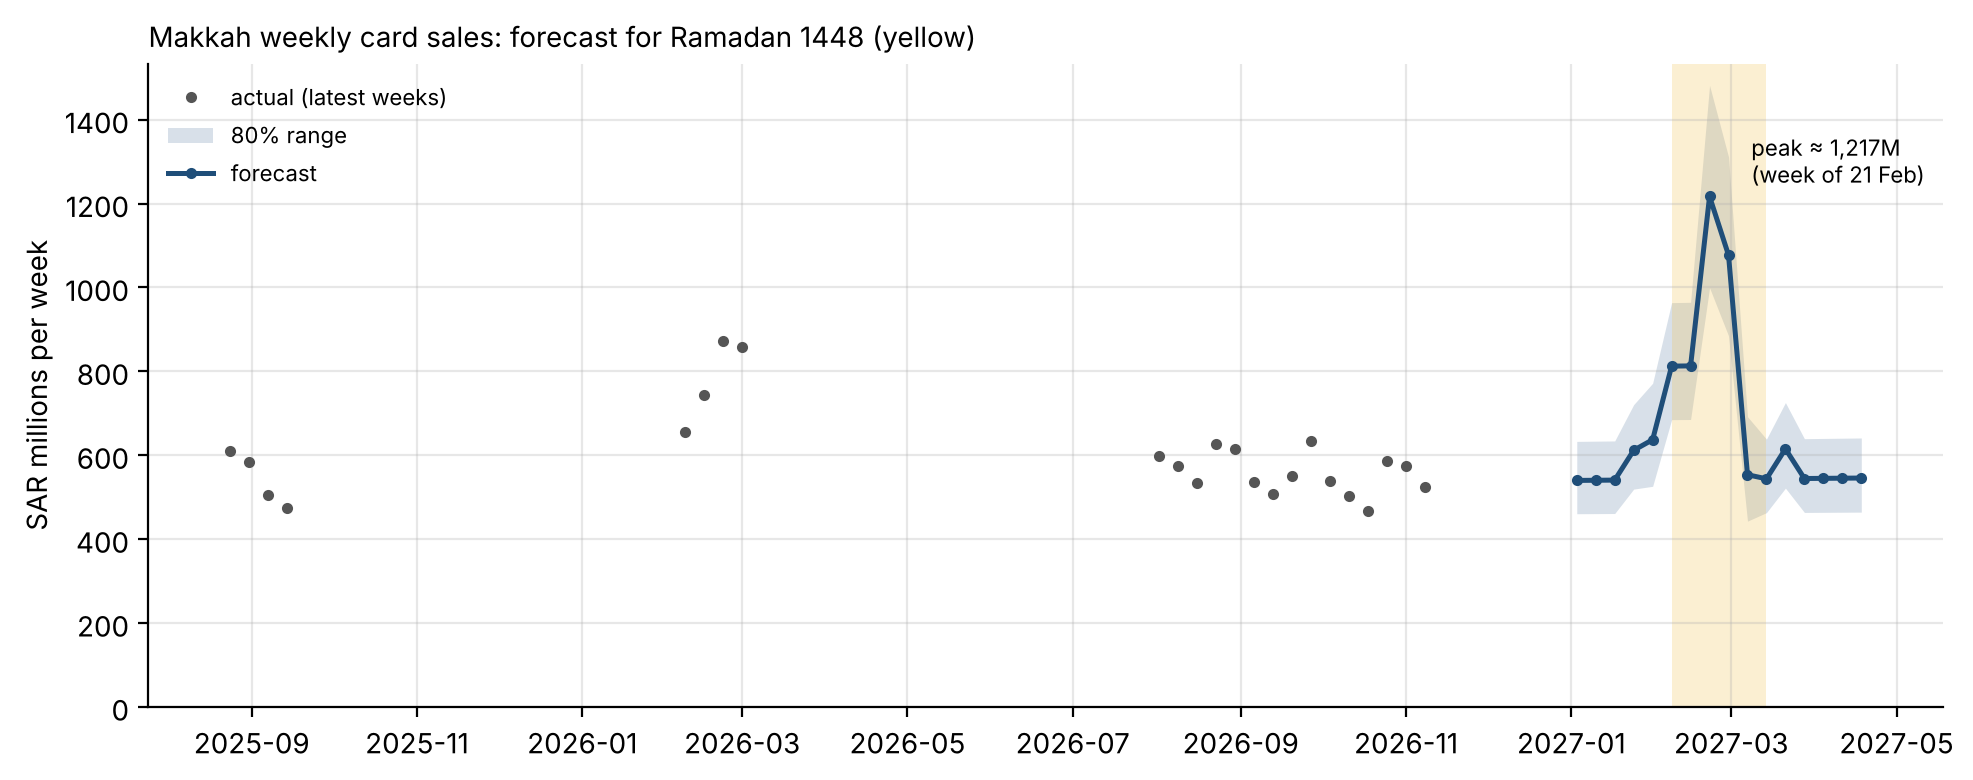

In [10]:
hist = m[m.starting_date >= "2025-08-01"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist.starting_date, hist.sales_m_sar, color="#555", lw=0, marker="o", ms=3, label="actual (latest weeks)")
ax.fill_between(fc.starting_date, fc.low, fc.high, color="#9fb3c8", alpha=0.4, lw=0, label="80% range")
ax.plot(fc.starting_date, fc.forecast, color="#1f4e79", lw=1.8, marker="o", ms=3, label="forecast")
for d in fc.loc[fc.season != "", "starting_date"]:
    ax.axvspan(d, d + pd.Timedelta(days=7), color="#f2c14e", alpha=0.25, lw=0)
peak = fc.loc[fc.forecast.idxmax()]
ax.annotate(f"peak ≈ {peak.forecast:,.0f}M\n(week of {peak.starting_date:%d %b})", (peak.starting_date, peak.forecast),
            xytext=(15, 5), textcoords="offset points", fontsize=8)
ax.set_ylim(0, None); ax.set_ylabel("SAR millions per week")
ax.set_title("Makkah weekly card sales: forecast for Ramadan 1448 (yellow)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left"); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "forecast_ramadan_1448.png", dpi=160); plt.show()

In [11]:
ram = fc[fc.season.str.startswith("Ramadan") | (fc.season == "Eid al-Fitr")]
print(f"Ramadan 1448 + Eid ({len(ram)} weeks): about {ram.forecast.sum() / 1000:.1f} billion SAR in card sales "
      f"(range {ram.low.sum() / 1000:.1f}–{ram.high.sum() / 1000:.1f}bn if every week sat at its low or high edge).")
print(f"Peak week: {peak.starting_date:%d %b %Y}, about {peak.forecast:,.0f}M SAR (80% range {peak.low:,.0f}–{peak.high:,.0f}M).")

Ramadan 1448 + Eid (5 weeks): about 4.5 billion SAR in card sales (range 3.7–5.4bn if every week sat at its low or high edge).
Peak week: 21 Feb 2027, about 1,217M SAR (80% range 999–1,482M).


## Limits

- **Hijri dates are calculated** (Umm al-Qura); if Ramadan starts a day earlier or later, the weeks shift by a day.
- **The trend assumes the last 2 years continue.** A shock (a new tourism policy, a change in Umrah numbers) would not be in the model.
- **Card sales only**: cash spending is not in the data.
- The 80% range treats each week on its own; the range for the whole season is narrower than adding up every week's edge.